# OOF evidence, uncertainty and horizon scenarios

This is cross-sectional grouped validation, not historical back-testing. Contract expiry year and expansion tags are proxy segments rather than product families.

In [1]:
from pathlib import Path
import sys
import json
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/config.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import DATA_PATH, OUTPUTS, PRIMARY_SCORE
from src.data_cleaning import validate_raw_frame, clean_dataset, TARGET
from src.model_training import latest_run, load_bundle, predict_bundle, sha256_file, frame_hash
from src.backtesting import read_evidence
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.dpi': 110})
run_dir = latest_run()
oof, manifest = read_evidence(run_dir)
bundle, _ = load_bundle(run_dir)
for name, expected in manifest['source_sha256'].items():
    assert sha256_file(ROOT / 'src' / name) == expected, f'Source changed since training: {name}'
for name, expected in manifest['warehouse_source_sha256'].items():
    assert sha256_file(ROOT / 'sql' / name) == expected, f'SQL changed since training: {name}'
assert sha256_file(run_dir / 'training_snapshot.csv') == manifest['training_snapshot_sha256']
display(pd.Series({
    'training_run': manifest['run_id'], 'model_version': manifest['model_version'],
    'training_created_at_utc': manifest['created_at_utc'],
    'feature_reference_date': bundle['reference_date'],
    'validation_source': manifest['prediction_source'],
}).to_frame('saved evidence'))
print('Notebook review updated: 2026-10-11. Results come from the saved training run above.')


,saved evidence
training_run,f0095e2660d447bd9df382f307062afb
model_version,v2.1.0-grouped-sigmoid-unweighted
training_created_at_utc,2026-10-11T09:40:45.905842+00:00
feature_reference_date,2026-10-01
validation_source,grouped_oof


Notebook review updated: 2026-10-11. Results come from the saved training run above.


In [2]:
metrics = pd.read_csv(run_dir / 'metrics.csv').set_index('model')
ci = pd.read_csv(run_dir / 'bootstrap_intervals.csv')
display(metrics.loc[['static_5', 'training_prevalence', PRIMARY_SCORE]])
display(ci[ci['model'] == PRIMARY_SCORE])
from src.backtesting import improvement_text
print(improvement_text(metrics.loc[PRIMARY_SCORE, 'brier_lift_vs_5_pct']))
print('A gain over 5% may only correct the portfolio rate; compare with training prevalence.')
rate_comparison = ci.loc[(ci.model == PRIMARY_SCORE) & (ci.baseline == 'training_prevalence')].iloc[0]
if rate_comparison.gain_ci_low > 0:
    print('The fixed-prediction interval supports lower Brier than training prevalence.')
else:
    print('No established Brier advantage over training prevalence: the interval includes zero or worse.')
print('Candidate ROC-AUC:', round(float(metrics.loc[PRIMARY_SCORE, 'roc_auc']), 6))


,mean_probability,observed_rate,bias,brier,log_loss,roc_auc,average_precision,ece_equal_width,ece_equal_count,brier_lift_vs_5_pct
model,,,,,,,,,,
static_5,0.050000,0.158174,-1.081741e-01,0.144857,0.517027,0.500000,0.158174,1.081741e-01,0.108174,0.000000
training_prevalence,0.158173,0.158174,-6.483716e-07,0.133165,0.436668,0.491357,0.155553,6.483716e-07,0.004959,8.071123
unweighted_ensemble_sigmoid,0.157952,0.158174,-2.220276e-04,0.133202,0.436824,0.500004,0.166414,2.220276e-04,0.019726,8.045411


,model,baseline,brier_gain,gain_ci_low,gain_ci_high,bias_ci_low,bias_ci_high
12,unweighted_ensemble_sigmoid,static_5,0.011654,0.008085,0.015435,-0.01739,0.016041
13,unweighted_ensemble_sigmoid,training_prevalence,-0.000037,-0.000289,0.000220,-0.01739,0.016041


Brier score improves by 8.05% relative to the baseline.
A gain over 5% may only correct the portfolio rate; compare with training prevalence.
No established Brier advantage over training prevalence: the interval includes zero or worse.
Candidate ROC-AUC: 0.500004


## Paired account uncertainty

1,000 resamples preserve sibling arrays. These intervals condition on saved predictions and omit refitting/model-selection uncertainty. Positive gain means lower Brier.

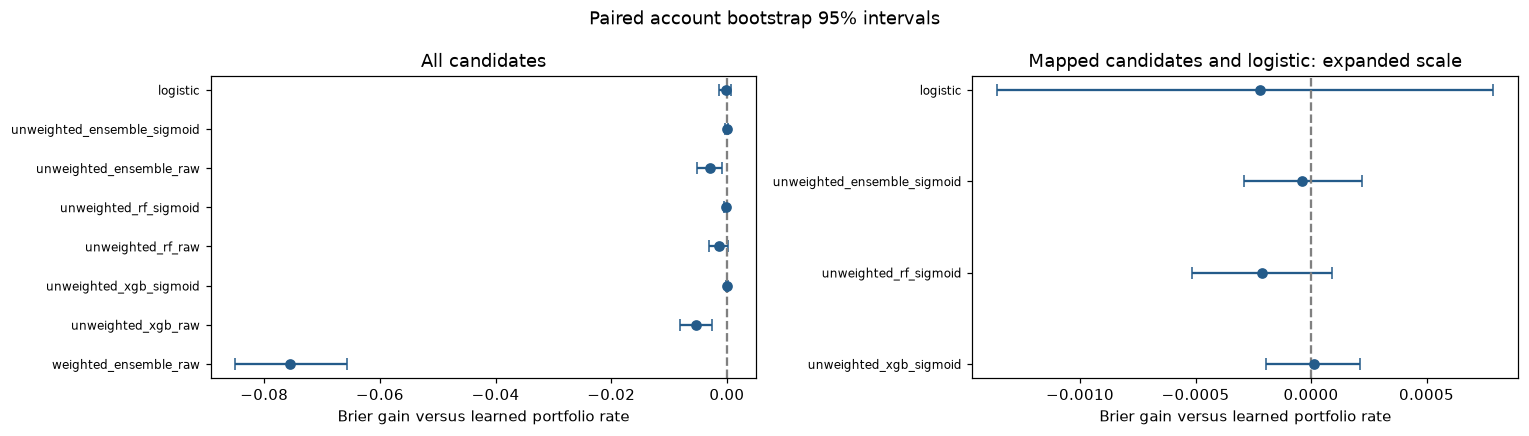

In [3]:
rows = ci[(ci['baseline'] == 'training_prevalence') & (ci['model'] != 'training_prevalence')].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, max(4, .4 * len(rows))))
close_view = rows.loc[rows.model.str.endswith('sigmoid') | rows.model.eq('logistic')]
for ax, subset, title in zip(axes, [rows, close_view],
                              ['All candidates', 'Mapped candidates and logistic: expanded scale']):
    ax.errorbar(subset.brier_gain, np.arange(len(subset)),
                xerr=[subset.brier_gain - subset.gain_ci_low, subset.gain_ci_high - subset.brier_gain],
                fmt='o', color='#245b8a', capsize=4)
    ax.axvline(0, color='gray', linestyle='--')
    ax.set_yticks(np.arange(len(subset)), subset['model'], fontsize=8)
    ax.set(xlabel='Brier gain versus learned portfolio rate', title=title)
fig.suptitle('Paired account bootstrap 95% intervals')
plt.tight_layout()
plt.show()


In [4]:
cohorts = pd.read_csv(run_dir / 'cohorts.csv')
buckets = pd.read_csv(run_dir / 'historical_exposure_buckets.csv')
display(cohorts)
display(buckets)
assert np.isclose(buckets.signed_historical_profit_usd.sum(), oof.historical_15yr_net_profit_usd.sum())
print('Dollar quantities above are signed historical exposure, not future loss or discounted CLV.')


,dimension,cohort,n,mean_probability,observed_rate,bias,brier,log_loss,roc_auc,average_precision,ece_equal_width,ece_equal_count,brier_gain,gain_ci_low,gain_ci_high,bias_ci_low,bias_ci_high
0,contract_year,2026,171,0.159158,0.169591,-0.010432,0.140912,0.455555,0.533269,0.200478,0.010432,0.075908,0.014220,0.002386,0.027025,-0.068968,0.042095
1,contract_year,2027,684,0.157844,0.152047,0.005797,0.128658,0.425257,0.535693,0.196039,0.005797,0.034022,0.010684,0.004350,0.016641,-0.021730,0.035297
2,contract_year,2028,697,0.158019,0.159254,-0.001235,0.134170,0.439511,0.477939,0.158537,0.001235,0.037943,0.011659,0.006119,0.017810,-0.029842,0.024431
3,contract_year,2029,332,0.157414,0.162651,-0.005237,0.136564,0.445368,0.463096,0.147210,0.005237,0.058236,0.012322,0.004330,0.020983,-0.045180,0.031620
4,expansion_potential_signal,High,401,0.157515,0.144638,0.012877,0.123644,0.413010,0.540213,0.178447,0.012877,0.029269,0.009030,0.001328,0.016248,-0.020961,0.049286
5,expansion_potential_signal,Low,790,0.157239,0.151899,0.005340,0.128789,0.425887,0.503470,0.179697,0.005340,0.044794,0.010420,0.005239,0.016207,-0.021859,0.029292
6,expansion_potential_signal,Medium,588,0.159130,0.180272,-0.021142,0.148587,0.474811,0.470348,0.176424,0.021142,0.050570,0.016158,0.009159,0.022839,-0.052329,0.010956
7,expansion_potential_signal,UNKNOWN,105,0.158388,0.133333,0.025054,0.116753,0.397343,0.454474,0.135284,0.025054,0.071747,0.005747,-0.007702,0.019749,-0.040455,0.089596


,risk_bucket,arrays,churns,observed_rate,signed_historical_profit_usd
0,CRITICAL,0.0,0.0,NaN,0.000000e+00
1,HIGH,0.0,0.0,NaN,0.000000e+00
2,MEDIUM,1661.0,263.0,0.158338,3.543979e+09
3,LOW,223.0,35.0,0.156951,5.091529e+08


Dollar quantities above are signed historical exposure, not future loss or discounted CLV.


Reporting preserves the sign of Brier improvement: a negative lift is deterioration. Empty exposure buckets have no observed event rate. Cohorts are descriptive diagnostics; neither contract year nor expansion category supplies product-family or matured observation-window evidence. OOF evidence is keyed, full precision and hash checked; full-fit production scores never replace it.

## Assumed years 2-15

Only the binary 12-month label is observed. Constant annual churn gives S(t)=(1-p)^t. The following plot and unit-cash-flow sensitivity are explicit scenarios, not a learned survival curve or dollar impact. Event/censoring history and time-indexed future cash flows are unavailable.

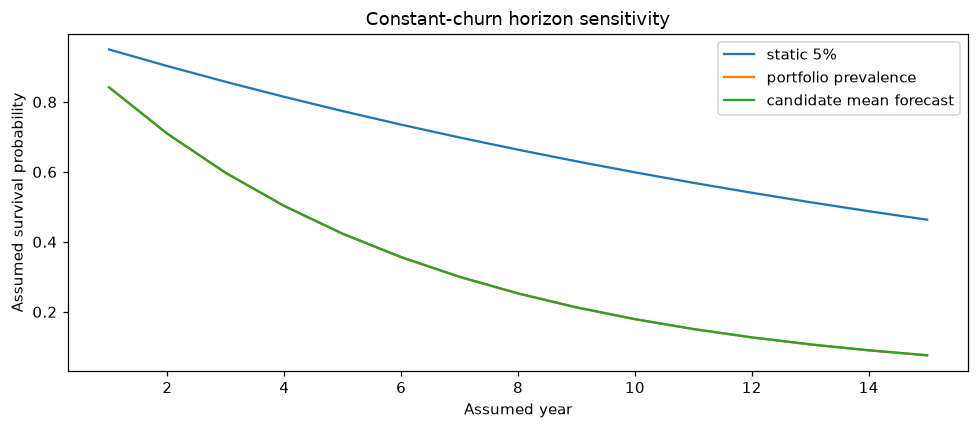

,scenario,discount_rate,value_per_one_unit_annual_cashflow
0,static 5%,0.00,10.197467
1,static 5%,0.05,7.382915
2,static 5%,0.10,5.630914
3,portfolio prevalence,0.00,4.919967
4,portfolio prevalence,0.05,3.896864
5,portfolio prevalence,0.10,3.201704
6,candidate mean forecast,0.00,4.926586
7,candidate mean forecast,0.05,3.901470
8,candidate mean forecast,0.10,3.205071


In [5]:
from src.scenarios import survival_scenario, discounted_clv_scenario
years = np.arange(1, 16)
rates = {'static 5%': .05, 'portfolio prevalence': float(oof[TARGET].mean()),
         'candidate mean forecast': float(oof[PRIMARY_SCORE].mean())}
for name, rate in rates.items():
    plt.plot(years, survival_scenario(rate), label=name)
plt.xlabel('Assumed year')
plt.ylabel('Assumed survival probability')
plt.title('Constant-churn horizon sensitivity')
plt.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame([
    {'scenario': name, 'discount_rate': r,
     'value_per_one_unit_annual_cashflow': float(discounted_clv_scenario(np.ones(15), p, r))}
    for name, p in rates.items() for r in [0, .05, .10]
]))
assert np.isclose(survival_scenario(.05)[-1], .463291230159753)
assert np.all(survival_scenario(0) == 1) and np.all(survival_scenario(1) == 0)
assert discounted_clv_scenario([-100, -100], 0, 0) == -200


## Final scoring delivery and integrity

Scoring loads the persisted transformer, unweighted models and probability maps. XGB/RF columns are individually sigmoid mapped. The ensemble maps 0.6 × raw XGB + 0.4 × raw RF; it is not a weighted mixture of already mapped columns. The immutable score directory contains the exact 25-column export, validated input snapshot, manifest and complete component explanations. Pre-export checks include warehouse precision, anomaly flags, probabilities, keys, dates and bucket consistency after rounding.

In [6]:
from src.config import SCORE_COLUMNS
from src.contracts import validate_scored_output
pointer = json.loads((OUTPUTS / 'latest_score_run.json').read_text())
score_dir = OUTPUTS / pointer['directory']
score_manifest = json.loads((score_dir / 'score_manifest.json').read_text())
assert score_manifest['training_run_id'] == manifest['run_id']
assert score_manifest['bundle_sha256'] == manifest['bundle_sha256']
for filename, field in [('CLV_SCORED_OUTPUT.csv', 'csv_sha256'),
                        ('input_snapshot.csv', 'snapshot_sha256'),
                        ('xgb_explanations.json', 'explanations_sha256')]:
    assert sha256_file(score_dir / filename) == score_manifest[field]
scored = pd.read_csv(score_dir / 'CLV_SCORED_OUTPUT.csv', dtype={'account_id': str, 'array_id': str})
validate_scored_output(scored)
snapshot = validate_raw_frame(score_dir / 'input_snapshot.csv')
reproduced = predict_bundle(bundle, snapshot)
for component in ['xgb', 'rf', 'ensemble']:
    np.testing.assert_allclose(scored[f'{component}_churn_probability'], reproduced[component], atol=5.1e-7)
assert sha256_file(OUTPUTS / 'CLV_SCORED_OUTPUT.csv') == score_manifest['csv_sha256']
assert sha256_file(OUTPUTS / 'backtesting_report.md') == sha256_file(run_dir / 'backtesting_report.md')
display(pd.Series({k: score_manifest[k] for k in [
    'score_run_id', 'training_run_id', 'model_version', 'rows', 'scored_at_utc',
    'reference_date', 'target_horizon', 'shap_units', 'deployment_status'
]}).to_frame('value'))
display(pd.DataFrame({'position': np.arange(1, len(SCORE_COLUMNS) + 1), 'export_column': SCORE_COLUMNS}))
display(scored.head(3))
print('PASS: scoring lineage, hashes, exact export contract and reproduced probabilities.')


,value
score_run_id,a8f54120f11648ea87a4028cc6c98e95
training_run_id,f0095e2660d447bd9df382f307062afb
model_version,v2.1.0-grouped-sigmoid-unweighted
rows,2000
scored_at_utc,2026-10-11 09:40:53
reference_date,2026-10-01
target_horizon,next_12_months_array_event
shap_units,raw_margin_log_odds
deployment_status,candidate; live Snowflake execution unverified


,position,export_column
0,1,account_id
1,2,array_id
2,3,contract_end_date
3,4,historical_15yr_net_profit_usd
4,5,current_capacity_tb
5,6,utilization_rate_pct
6,7,raw_utilization_rate_pct
7,8,utilization_capped
8,9,is_over_utilized_raw
9,10,is_negative_profit


,account_id,array_id,contract_end_date,historical_15yr_net_profit_usd,current_capacity_tb,utilization_rate_pct,raw_utilization_rate_pct,utilization_capped,is_over_utilized_raw,is_negative_profit,...,ensemble_churn_probability,churn_risk_bucket,shap_top_feature_1,shap_top_feature_1_value,shap_top_feature_2,shap_top_feature_2_value,shap_top_feature_3,shap_top_feature_3_value,scored_at,model_version
0,ACC_1000,ARR_5000,2026-10-01,146797,1382,0.59,0.59,0.59,False,False,...,0.157704,MEDIUM,days_to_contract_end,0.282470,profit_per_tb,0.202917,signed_log_profit,0.101801,2026-10-11 09:40:53,v2.1.0-grouped-sigmoid-unweighted
1,ACC_1001,ARR_5001,2026-10-01,1236408,1809,0.93,0.93,0.93,False,False,...,0.157506,MEDIUM,days_to_contract_end,0.466661,signed_log_profit,0.349695,profit_per_tb,0.331495,2026-10-11 09:40:53,v2.1.0-grouped-sigmoid-unweighted
2,ACC_1002,ARR_5002,2026-10-02,2790632,605,1.28,1.28,1.00,True,False,...,0.158404,MEDIUM,profit_per_tb,-0.270406,signed_log_profit,0.173087,current_capacity_tb,-0.148624,2026-10-11 09:40:53,v2.1.0-grouped-sigmoid-unweighted


PASS: scoring lineage, hashes, exact export contract and reproduced probabilities.


## Account array-event summaries

Account aggregation reports conditional probability bounds for any/all array events without an independence assumption. These are not account-cancellation probabilities. Incomplete array prediction coverage withholds bounds; incomplete label coverage withholds observed proxies. The OOF summary includes coverage for the full supplied population, including accounts with no labeled arrays.

In [7]:
analytics_dir = score_dir / 'submission_analytics'
analytics_manifest = json.loads((analytics_dir / 'analytics_manifest.json').read_text())
assert analytics_manifest['training_run_id'] == manifest['run_id']
assert analytics_manifest['score_manifest_sha256'] == sha256_file(score_dir / 'score_manifest.json')
for filename, metadata in analytics_manifest['artifacts'].items():
    assert sha256_file(analytics_dir / filename) == metadata['sha256']
accounts = pd.read_csv(analytics_dir / 'account_array_event_summary.csv')
account_oof = pd.read_csv(analytics_dir / 'account_oof_array_event_summary.csv')
display(accounts.head(5))
display(account_oof[['complete_probability_coverage', 'complete_label_coverage']].value_counts().to_frame('accounts'))
assert len(accounts) == snapshot.account_id.nunique()
assert np.isclose(accounts.signed_historical_profit_usd.sum(), snapshot.historical_15yr_net_profit_usd.sum())
print(analytics_manifest['account_semantics'])


,account_id,arrays_expected,arrays_scored,complete_probability_coverage,mean_scored_array_event_probability,max_scored_array_event_probability,any_array_event_probability_lower_bound,any_array_event_probability_upper_bound,all_arrays_event_probability_lower_bound,all_arrays_event_probability_upper_bound,complete_label_coverage,observed_any_array_event_proxy,observed_all_arrays_event_proxy,signed_historical_profit_usd,current_capacity_tb,prediction_source,semantics
0,ACC_1000,2,2,True,0.157903,0.158102,0.158102,0.315806,0.0,0.157704,True,1.0,0.0,2108166.0,1966.0,full_fit_scoring,array_event_summary_not_account_cancellation
1,ACC_1001,2,2,True,0.157839,0.158172,0.158172,0.315678,0.0,0.157506,True,1.0,0.0,1501166.0,2943.0,full_fit_scoring,array_event_summary_not_account_cancellation
2,ACC_1002,2,2,True,0.158148,0.158404,0.158404,0.316297,0.0,0.157893,True,1.0,0.0,5882315.0,2034.0,full_fit_scoring,array_event_summary_not_account_cancellation
3,ACC_1003,2,2,True,0.157979,0.158237,0.158237,0.315958,0.0,0.157722,True,0.0,0.0,3101350.0,2262.0,full_fit_scoring,array_event_summary_not_account_cancellation
4,ACC_1004,2,2,True,0.158188,0.158371,0.158371,0.316376,0.0,0.158005,False,NaN,NaN,5567543.0,561.0,full_fit_scoring,array_event_summary_not_account_cancellation


,,accounts
complete_probability_coverage,complete_label_coverage,
True,True,889
False,False,111


Bounds on any/all array events; no account-cancellation prediction or independence assumption


## Capacity diagnostics and per-array 15-year delivery

Capacity headroom/pressure values are arithmetic at the reported current load, preserving supplied tags and anomaly flags. Out-of-range utilization may be a data defect; no future expansion is inferred from it. Each array has a constant-rate 15-year scenario compared with 5%. Dollar scenarios require explicit future cash flows; the delivered default uses one unit annually. The learned binary array event does not establish absorbing loss or commercial renewal.

In [8]:
capacity = pd.read_csv(analytics_dir / 'capacity_expansion_signals.csv')
horizons = pd.read_csv(analytics_dir / 'fifteen_year_scenarios.csv')
cash_values = pd.read_csv(analytics_dir / 'discounted_cash_flow_scenarios.csv')
display(capacity.head(5))
display(horizons[['account_id', 'array_id', 'scenario', 'assumed_annual_event_probability',
                  'assumed_survival_year_1', 'assumed_survival_year_5',
                  'assumed_survival_year_15', 'assumed_event_by_year_15']].head(5))
display(cash_values.groupby(['scenario', 'discount_rate', 'value_units']).scenario_discounted_value.agg(['count', 'mean']))
assert len(horizons) == 2 * len(snapshot)
for year in range(1, 16):
    np.testing.assert_allclose(horizons[f'assumed_survival_year_{year}'],
                               (1 - horizons.assumed_annual_event_probability)**year, atol=1e-14)
print(analytics_manifest['horizon_semantics'])
print(analytics_manifest['cash_flow_semantics'])


,account_id,array_id,expansion_potential_signal,current_capacity_tb,utilization_rate_pct,additional_capacity_to_reach_100pct_tb,spare_capacity_at_reported_load_tb,reported_over_capacity,expansion_signal_unknown,signal_type
0,ACC_1000,ARR_5000,Medium,1382,0.59,0.00,566.62,False,False,current_load_arithmetic_and_supplied_tag_not_f...
1,ACC_1001,ARR_5001,UNKNOWN,1809,0.93,0.00,126.63,False,True,current_load_arithmetic_and_supplied_tag_not_f...
2,ACC_1002,ARR_5002,Low,605,1.28,169.40,0.00,True,False,current_load_arithmetic_and_supplied_tag_not_f...
3,ACC_1003,ARR_5003,Low,1567,0.47,0.00,830.51,False,False,current_load_arithmetic_and_supplied_tag_not_f...
4,ACC_1004,ARR_5004,Low,488,1.22,107.36,0.00,True,False,current_load_arithmetic_and_supplied_tag_not_f...


,account_id,array_id,scenario,assumed_annual_event_probability,assumed_survival_year_1,assumed_survival_year_5,assumed_survival_year_15,assumed_event_by_year_15
0,ACC_1000,ARR_5000,calibrated_array_event_rate,0.157704,0.842296,0.423958,0.076202,0.923798
1,ACC_1001,ARR_5001,calibrated_array_event_rate,0.157506,0.842494,0.424457,0.076472,0.923528
2,ACC_1002,ARR_5002,calibrated_array_event_rate,0.158404,0.841596,0.422199,0.075258,0.924742
3,ACC_1003,ARR_5003,calibrated_array_event_rate,0.157722,0.842278,0.423915,0.076179,0.923821
4,ACC_1004,ARR_5004,calibrated_array_event_rate,0.158371,0.841629,0.422282,0.075302,0.924698


count  \
scenario                    discount_rate value_units                        
calibrated_array_event_rate 0.00          one_unit_annual_cash_flow   2000   
                            0.05          one_unit_annual_cash_flow   2000   
                            0.10          one_unit_annual_cash_flow   2000   
static_5pct                 0.00          one_unit_annual_cash_flow   2000   
                            0.05          one_unit_annual_cash_flow   2000   
                            0.10          one_unit_annual_cash_flow   2000   

                                                                          mean  
scenario                    discount_rate value_units                           
calibrated_array_event_rate 0.00          one_unit_annual_cash_flow   4.920386  
                            0.05          one_unit_annual_cash_flow   3.897155  
                            0.10          one_unit_annual_cash_flow   3.201916  
static_5pct                 0.00          one_unit_annual_cash_flow  10.197467  
                            0.05          one_unit_annual_cash_flow   7.382915  
                            0.10          one_unit_annual_cash_flow   5.630914

Constant annual event-rate assumption; not learned survival or verified renewal
Explicit supplied future USD cash flows, or one unit annually; historical profit is never extrapolated


## Guarded future-data workflows

The dated workflow supports array-event, actual account-cancellation and realized capacity-expansion targets once their business definitions and snapshot/outcome dates are supplied. Training labels must be available before each cutoff; validation outcomes must have matured by evaluation-as-of. Each window fits its own preprocessing and grouped calibration. Supplied expansion tags are excluded when predicting future expansion. Real product-family mappings enable additional XGB/RF/ensemble cohort comparisons; expiry years and expansion tags are not renamed product families. Header-only contracts are documented in docs/REMAINING_DATA_CONTRACTS.md. Synthetic regression fixtures demonstrate software behavior only.

In [9]:
from src.temporal_validation import validate_history
try:
    validate_history(DATA_PATH)
except ValueError as error:
    print('Expected data-availability guard:', error)
else:
    raise AssertionError('Cross-sectional input must not pass as historical evidence')
print('Real product-family evaluation:', analytics_manifest['product_cohort_status'])
display(pd.DataFrame([
    {'contract': path.name, 'fields': ', '.join(pd.read_csv(path).columns), 'observations': len(pd.read_csv(path))}
    for path in sorted((ROOT / 'data/contracts').glob('*.csv'))
]))
print('No real historical/cancellation/expansion-outcome performance is claimed from these empty contracts.')


Expected data-availability guard: Dated validation needs explicit snapshot/outcome fields: ['feature_as_of', 'label_available_at', 'label_window_end', 'observation_date']
Real product-family evaluation: unavailable_no_product_mapping


,contract,fields,observations
0,dated_account_outcomes.csv,"account_id, observation_date, feature_as_of, l...",0
1,dated_array_outcomes.csv,"account_id, array_id, observation_date, featur...",0
2,dated_expansion_outcomes.csv,"account_id, array_id, observation_date, featur...",0
3,future_cash_flows.csv,"account_id, array_id, year, annual_cash_flow_usd",0
4,product_family_mapping.csv,"account_id, array_id, product_family",0


No real historical/cancellation/expansion-outcome performance is claimed from these empty contracts.


## Snowflake ingestion implementation and acceptance

Run setup, DDL and the procedure script in a fresh selected sandbox. The fixed internal CLV_STAGE and CSV format match the 25 export columns. The six arguments are FILE_NAME, TARGET_MODEL_VERSION, RUN_ID, TRAINING_RUN_ID, SNAPSHOT_SHA256 and BUNDLE_SHA256. Filenames are validated relative paths. Each call uses its own temporary staging table; one transaction writes immutable history, the physical CLV_SCORED_OUTPUT table and the run ledger. Older timestamps cannot replace newer current scores; ties use lexical RUN_ID order, consistent with the reconciliation view. Identical payload/lineage replays return REPLAY_UNCHANGED; changed same-run payloads are rejected. Failures roll back and are logged. Standard-table keys are informational: serialize ingestion through one writer; concurrent same-run idempotency is not established.

In [10]:
ddl = (ROOT / 'sql/ddl_clv_scored_output.sql').read_text(encoding='utf-8-sig')
body = ddl.split('CREATE TABLE IF NOT EXISTS CLV_SCORE_STAGING_TEMPLATE (')[1].split(');')[0]
assert [line.strip().split()[0].lower() for line in body.splitlines() if line.strip()] == SCORE_COLUMNS
assert 'CREATE TABLE IF NOT EXISTS CLV_SCORED_OUTPUT LIKE CLV_SCORED_HISTORY' in ddl
handler = (ROOT / 'sql/stored_proc_scoring_pipeline.sql').read_text(encoding='utf-8-sig').split('$$')[1]
compile(handler, 'snowflake_handler', 'exec')
assert 'MERGE INTO CLV_SCORED_OUTPUT' in handler
print('PASS: local SQL column order and embedded Python syntax only. Live execution remains unverified.')
print((ROOT / 'sql/sandbox_acceptance.sql').read_text(encoding='utf-8-sig'))


PASS: local SQL column order and embedded Python syntax only. Live execution remains unverified.
-- Execute only in a sandbox after setting role/warehouse/database/schema.
-- Record all query IDs and procedure results. These instructions are not evidence of execution.
-- 1. Stage a unique fixture file; call the six-argument procedure with score_manifest.json values.
-- 2. Repeat identical call: expect REPLAY_UNCHANGED and unchanged history counts/payload.
-- 3. Stage changed scores under the same RUN_ID: expect rejection.
-- 4. New RUN_ID with later scores: expect new history rows and current table updated.
-- 5. Stage duplicate keys, wrong version, invalid probability or bucket: expect rejection.
-- 6. Simulate failed COPY: history/ledger must remain unchanged; inspect failure log.
-- 7. Enforce one writer job; do not concurrently retry the same RUN_ID.
-- 8. Load an older timestamp: history grows, current-score rows must not regress.
-- 9. Fail the current-table MERGE: history/curren

## Reproduction and final checks

CPython 3.12.10 and requirements-lock.txt pin the tested environment. From the project root, run `python -m unittest discover -s tests -p "test_*.py" -v` and `python tests/verify_all_steps.py`. The regression suite covers input rejection, fold isolation, persisted state, hash/lineage tampering, unsupported fitted evidence, report preservation, export rounding, SHAP reconstruction, account bounds/coverage, signed future cash flows, chronological maturity and target guards, genuine product mappings, and warehouse transaction/replay control flow. The verifier is read-only and does not regenerate predictions or overwrite reports. The three notebooks read the current saved artifacts; the maintained generator is tools/build_notebooks.py. Archived submissions, earlier runs and legacy script aliases are excluded from the final delivery.

## Operational recommendation

Do not claim behavioral targeting lift from probability calibration alone. Preserve immutable OOF and scoring lineage, retain the prevalence challenger, obtain mature longitudinal outcomes, and run Snowflake sandbox acceptance before deployment. SQL static checks are not evidence of warehouse execution.